# Assignment 6 — Histogram Equalization and Histogram Matching

### Requirements
Run this cell once to install the libraries used in this notebook.

In [ ]:
%pip install numpy matplotlib opencv-python scikit-image

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = data.moon()   # 'moon (low contrast)' test image from scikit-image

print("Image size:", img.shape, "| dtype:", img.dtype, "| min/max:", img.min(), img.max())

Image size: (512, 512) | dtype: uint8 | min/max: 0 255


## Question 1

> **Question 1:** Write a program to enhance the contrast of the input grayscale image using histogram equalization. Display the original image and the equalized image.

For an image with $MN$ pixels and $L = 256$ levels:
$$ p(r_k) = \frac{n_k}{MN}, \qquad s_k = T(r_k) = (L-1)\sum_{j=0}^{k} p(r_j) $$
Each pixel value $r_k$ is replaced by the rounded $s_k$, which spreads the histogram over the whole intensity range.

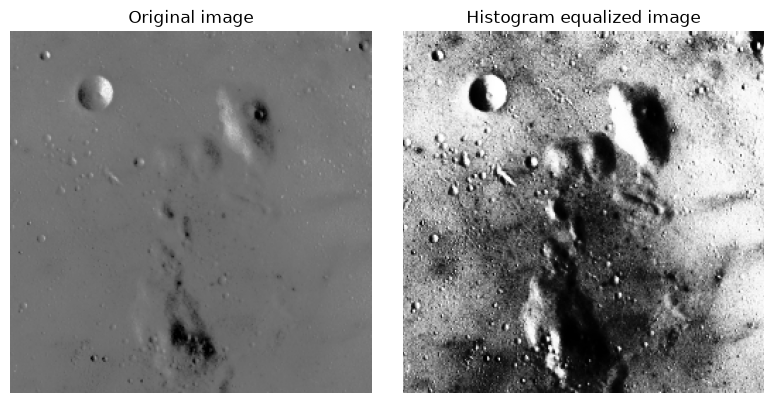

In [3]:
def histogram(image):
    """Count of pixels at every intensity 0..255."""
    return np.bincount(image.ravel(), minlength=256)


def equalization_map(image, L=256):
    pdf = histogram(image) / image.size
    cdf = np.cumsum(pdf)
    return (L - 1) * cdf                    # T(r) as floats


def equalize(image):
    T = np.round(equalization_map(image)).astype(np.uint8)
    return T[image]                         # apply the mapping as a look-up table


eq = equalize(img)
show([img, eq], ['Original image', 'Histogram equalized image'])

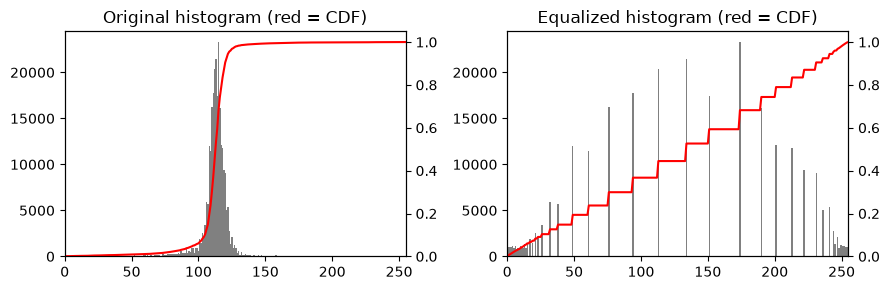

In [4]:
def plot_hist_cdf(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4.5 * len(images), 3))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        h = histogram(im)
        ax.bar(np.arange(256), h, width=1, color='gray')
        ax2 = ax.twinx()
        ax2.plot(np.cumsum(h) / im.size, 'r'); ax2.set_ylim(0, 1.05)
        ax.set_title(t); ax.set_xlim(0, 255)
    plt.tight_layout(); plt.show()

plot_hist_cdf([img, eq], ['Original histogram (red = CDF)', 'Equalized histogram (red = CDF)'])

After equalization the CDF is close to a straight line, which means the intensities are roughly uniformly distributed.

### Verification against OpenCV `equalizeHist`
OpenCV uses a slightly different formula ($\frac{cdf - cdf_{min}}{MN - cdf_{min}}$), so a few levels can differ by a small amount.

Mean |difference|: 0.13 | max |difference|: 1


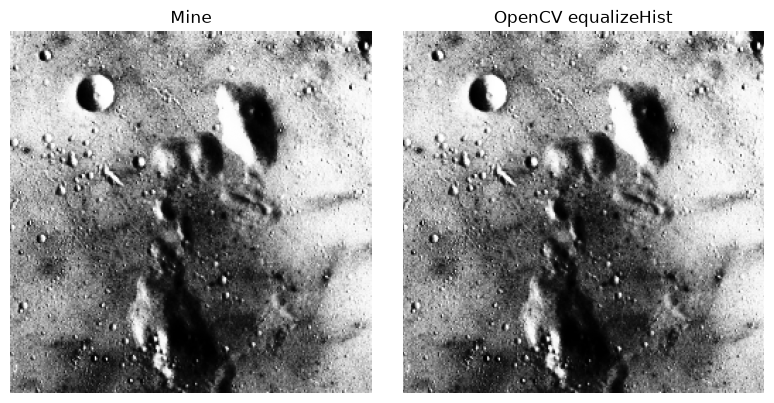

In [5]:
eq_cv = cv2.equalizeHist(img)
diff = np.abs(eq.astype(int) - eq_cv.astype(int))
print("Mean |difference|:", diff.mean().round(3), "| max |difference|:", diff.max())
show([eq, eq_cv], ['Mine', 'OpenCV equalizeHist'])

## Question 2

> **Question 2:** Write a program to perform histogram matching of the input image with that of a reference image using histogram equalization.

Steps:
1. Equalize the input image: $s = T(r)$
2. Equalize the reference image: $s = G(z)$
3. For every $r$, choose the $z$ with $G(z)$ closest to $T(r)$, i.e. $z = G^{-1}(T(r))$
4. Map every input pixel $r \rightarrow z$

The output then has a histogram shaped like the reference image's histogram.

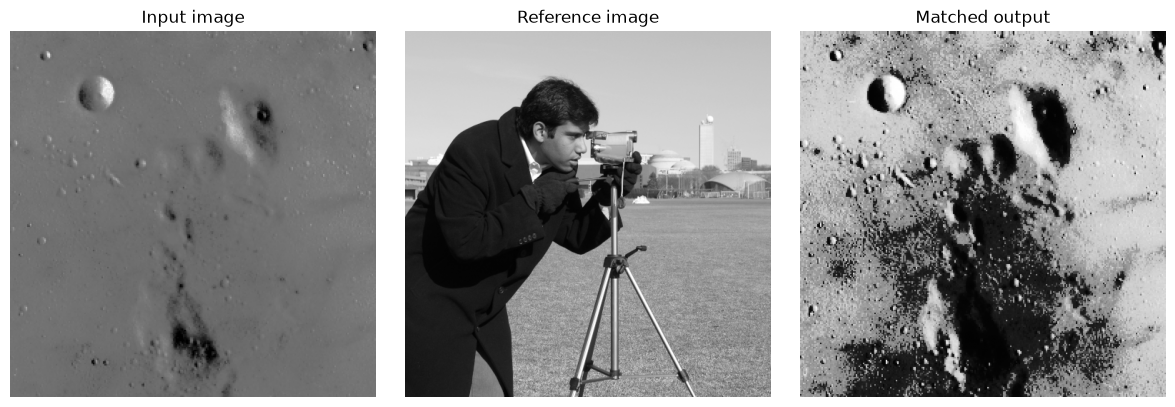

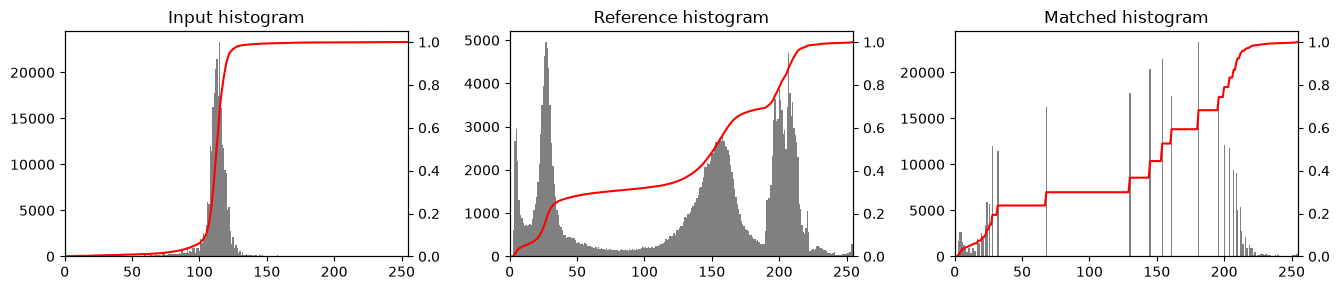

In [6]:
REF_PATH = None   # path of your own reference image
ref = cv2.imread(REF_PATH, cv2.IMREAD_GRAYSCALE) if REF_PATH else data.camera()


def match_histogram(source, reference):
    T = equalization_map(source)       # s = T(r)
    G = equalization_map(reference)    # s = G(z)
    # inverse mapping: for each r find z minimising |G(z) - T(r)|
    mapping = np.argmin(np.abs(G[None, :] - T[:, None]), axis=1).astype(np.uint8)
    return mapping[source], mapping


matched, mapping = match_histogram(img, ref)
show([img, ref, matched], ['Input image', 'Reference image', 'Matched output'])
plot_hist_cdf([img, ref, matched], ['Input histogram', 'Reference histogram', 'Matched histogram'])

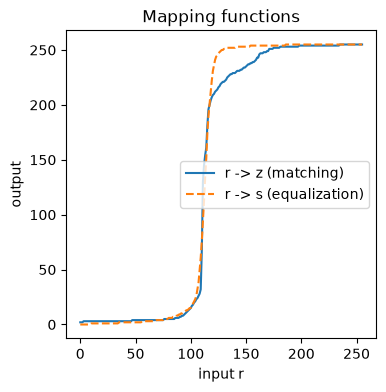

In [7]:
plt.figure(figsize=(4, 4))
plt.plot(mapping, label='r -> z (matching)')
plt.plot(np.round(equalization_map(img)), '--', label='r -> s (equalization)')
plt.xlabel('input r'); plt.ylabel('output'); plt.title('Mapping functions'); plt.legend(); plt.show()

### Verification against scikit-image `match_histograms`

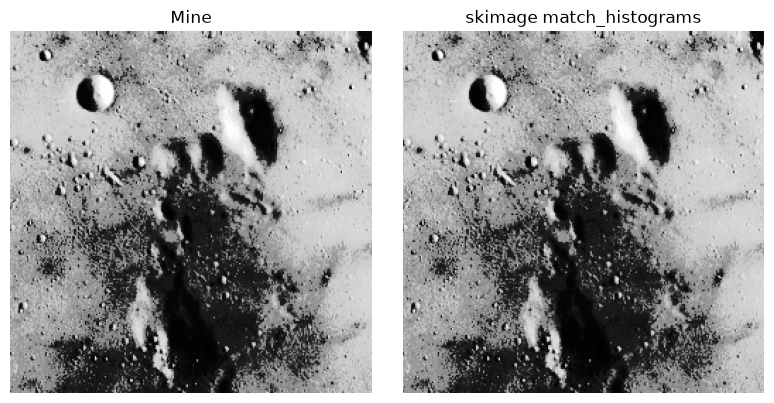

Mean |difference|: 0.462


In [8]:
from skimage.exposure import match_histograms
matched_sk = match_histograms(img, ref).astype(np.uint8)
show([matched, matched_sk], ['Mine', 'skimage match_histograms'])
print("Mean |difference|:", np.abs(matched.astype(int) - matched_sk.astype(int)).mean().round(3))

**Observations:**
- The moon image has a narrow histogram (low contrast). Equalization spreads it over 0–255, so surface detail becomes much clearer.
- Equalization always aims for a *flat* histogram. Histogram matching aims for the *reference* image's histogram, so the output takes on the reference image's overall brightness and contrast.
- The CDF of the matched image follows the CDF of the reference image closely.